# Traffic Sign Classification Using CNN

Complete Jupyter Notebook for the **GTSRB (German Traffic Sign Recognition Benchmark)** dataset. It loads the existing `Train/`, `Test/`, and CSV files, preprocesses images to **30×30 RGB**, trains a CNN for **43 classes**, evaluates it, and saves the trained model.


## 1. Import required libraries

In [1]:
%pip install -q opencv-python scikit-learn seaborn tensorflow

import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print('TensorFlow version:', tf.__version__)

Note: you may need to restart the kernel to use updated packages.
TensorFlow version: 2.22.0-rc0


## 2. Set dataset location and read CSV files

In [2]:

candidates = ['.', './archive']
DATASET_PATH = next((p for p in candidates if os.path.exists(os.path.join(p, 'Train.csv'))), None)
if DATASET_PATH is None:
    raise FileNotFoundError("Train.csv was not found. Put this notebook beside Train.csv, or update DATASET_PATH.")

train_csv_path = os.path.join(DATASET_PATH, 'Train.csv')
test_csv_path = os.path.join(DATASET_PATH, 'Test.csv')
train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)

print('Dataset folder:', os.path.abspath(DATASET_PATH))
print('Training records:', len(train_df))
print('Testing records:', len(test_df))
print('CSV columns:', train_df.columns.tolist())
train_df.head()

Dataset folder: C:\Users\aditi vinod padir\Downloads\archive
Training records: 39209
Testing records: 12630
CSV columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


## 3. Load images and preprocess them

Images are resized to 30×30 pixels, converted from BGR to RGB, and kept as `uint8` initially to reduce memory use. Normalization is performed before training.

In [3]:
IMG_SIZE = 30
NUM_CLASSES = 43

def resolve_image_path(relative_path):
    relative_path = str(relative_path).replace('\\\\', '/')
    return os.path.join(DATASET_PATH, relative_path)

def load_images(dataframe, split_name):
    images = []
    labels = []
    missing_files = []
    for row in dataframe.itertuples(index=False):
        image_path = resolve_image_path(getattr(row, 'Path'))
        image = cv2.imread(image_path)
        if image is None:
            missing_files.append(image_path)
            continue
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        images.append(image)
        labels.append(int(getattr(row, 'ClassId')))
    if missing_files:
        print(f'Warning: {len(missing_files)} {split_name} image(s) could not be read. First missing path:', missing_files[0])
    return np.asarray(images, dtype=np.uint8), np.asarray(labels, dtype=np.int64)

X, y = load_images(train_df, 'training')
X_test, y_test = load_images(test_df, 'test')

print('Training image shape:', X.shape)
print('Training labels shape:', y.shape)
print('Test image shape:', X_test.shape)
print('Number of classes:', len(np.unique(y)))

assert len(X) > 0 and len(X_test) > 0, 'No images were loaded. Check CSV Path values and dataset folder.'
assert set(np.unique(y)).issubset(set(range(NUM_CLASSES))), 'Unexpected class ID found.'

Training image shape: (39209, 30, 30, 3)
Training labels shape: (39209,)
Test image shape: (12630, 30, 30, 3)
Number of classes: 43


## 4. Display sample traffic sign images

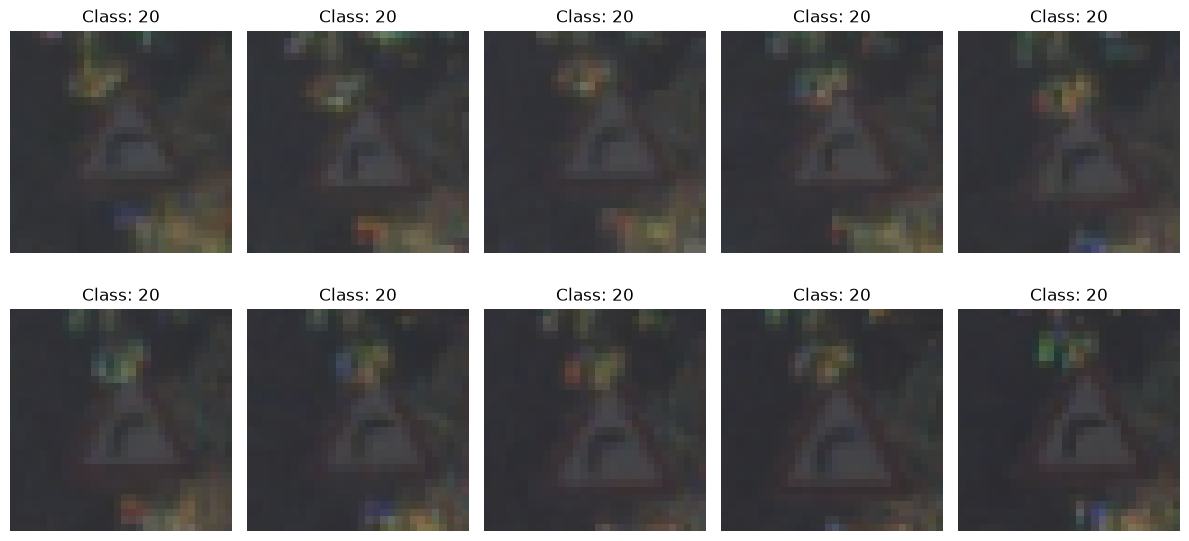

In [4]:
plt.figure(figsize=(12, 6))
for i in range(min(10, len(X))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i])
    plt.title(f'Class: {y[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 5. Split training data and normalize images

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print('X_train:', X_train.shape)
print('X_val:', X_val.shape)
print('X_test:', X_test.shape)
print('Pixel range:', X_train.min(), 'to', X_train.max())

X_train: (31367, 30, 30, 3)
X_val: (7842, 30, 30, 3)
X_test: (12630, 30, 30, 3)
Pixel range: 0.0 to 1.0


## 6. Build the CNN model

In [6]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 366,539 (1.40 MB)

 Trainable params: 366,347 (1.40 MB)

 Non-trainable params: 192 (768.00 B)

## 7. Train the model

In [8]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
    ModelCheckpoint('best_traffic_sign_model.keras', monitor='val_accuracy', save_best_only=True)
]


history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 158s 321ms/step - accuracy: 0.9912 - loss: 0.0274 - val_accuracy: 0.9977 - val_loss: 0.0116 - learning_rate: 5.0000e-04
Epoch 2/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 216s 349ms/step - accuracy: 0.9918 - loss: 0.0278 - val_accuracy: 0.9974 - val_loss: 0.0135 - learning_rate: 5.0000e-04
Epoch 3/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 164s 333ms/step - accuracy: 0.9915 - loss: 0.0262 - val_accuracy: 0.9980 - val_loss: 0.0126 - learning_rate: 5.0000e-04
Epoch 4/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 165s 336ms/step - accuracy: 0.9933 - loss: 0.0201 - val_accuracy: 0.9981 - val_loss: 0.0104 - learning_rate: 2.5000e-04
Epoch 5/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 163s 331ms/step - accuracy: 0.9953 - loss: 0.0164 - val_accuracy: 0.9980 - val_loss: 0.0111 - learning_rate: 2.5000e-04
Epoch 6/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 150s 305ms/step - accuracy: 0.9948 - loss: 0.0157 - val_accuracy: 0.9981 - val_loss: 0.0112 - learning_rate: 2.5000e-04
Epoch 7/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 

## 8. Plot training and validation accuracy/loss

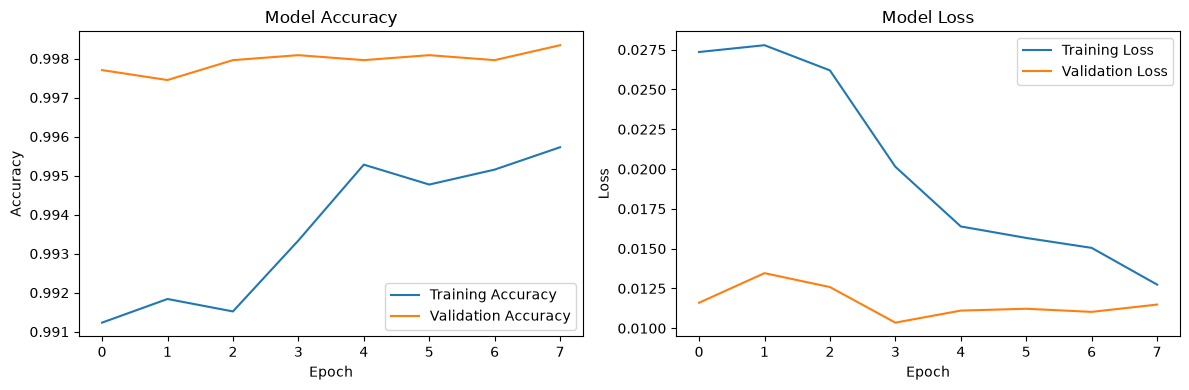

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 9. Evaluate on the test dataset

In [10]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f'Test Accuracy: {test_accuracy * 100:.2f}%')
print(f'Test Loss: {test_loss:.4f}')

395/395 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - accuracy: 0.9807 - loss: 0.0866
Test Accuracy: 98.07%
Test Loss: 0.0866


## 10. Classification report and confusion matrix

395/395 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        60
           1       0.98      1.00      0.99       720
           2       0.99      1.00      1.00       750
           3       0.94      0.98      0.96       450
           4       1.00      0.99      0.99       660
           5       0.98      1.00      0.99       630
           6       1.00      0.83      0.91       150
           7       0.99      0.99      0.99       450
           8       0.99      0.97      0.98       450
           9       0.99      1.00      0.99       480
          10       1.00      1.00      1.00       660
          11       0.98      0.99      0.99       420
          12       1.00      0.96      0.98       690
          13       0.98      1.00      0.99       720
          14       1.00      1.00      1.00       270
          15       0.95      1.00      0.97       210
          16       1.00      1.00     

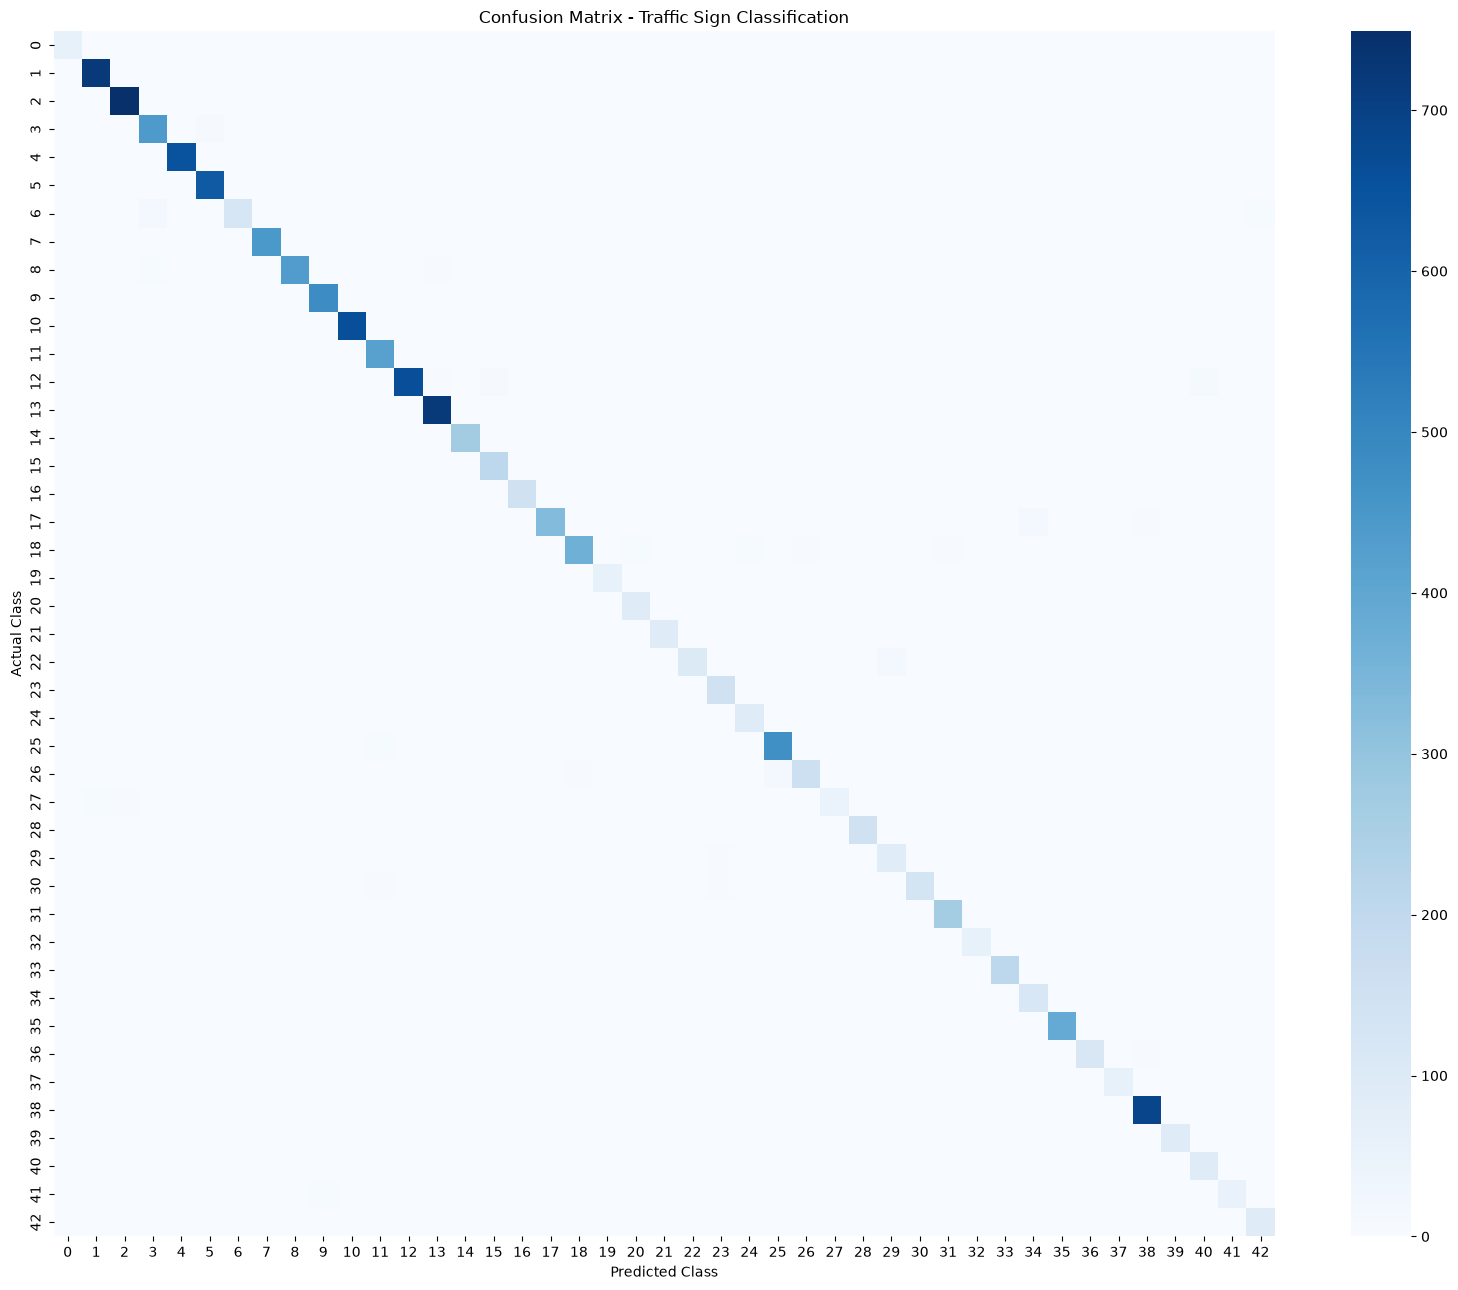

In [11]:
y_pred_prob = model.predict(X_test, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(16, 13))
sns.heatmap(cm, cmap='Blues', annot=False, cbar=True)
plt.title('Confusion Matrix - Traffic Sign Classification')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.show()

## 11. Display predictions on sample test images

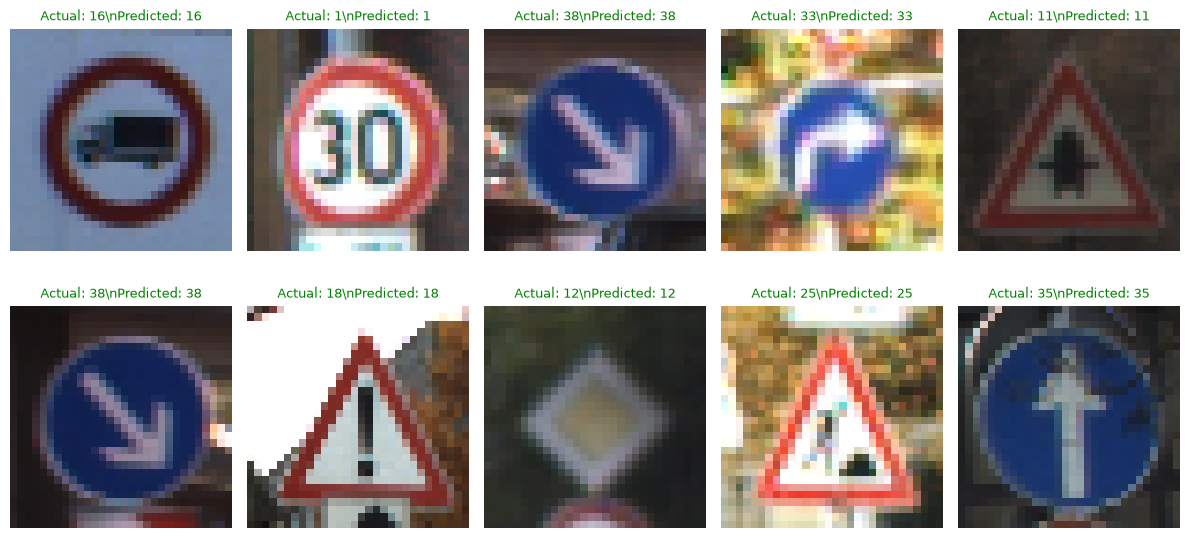

In [12]:
plt.figure(figsize=(12, 6))
sample_count = min(10, len(X_test))
for i in range(sample_count):
    plt.subplot(2, 5, i + 1)
    plt.imshow((X_test[i] * 255).astype('uint8'))
    color = 'green' if y_pred[i] == y_test[i] else 'red'
    plt.title(f'Actual: {y_test[i]}\\nPredicted: {y_pred[i]}', color=color, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 12. Save the trained model

In [22]:
model.save('traffic_sign_model.keras')
print('Model saved successfully as traffic_sign_model.keras')

Model saved successfully as traffic_sign_model.keras


## 13. Predict a single traffic sign image


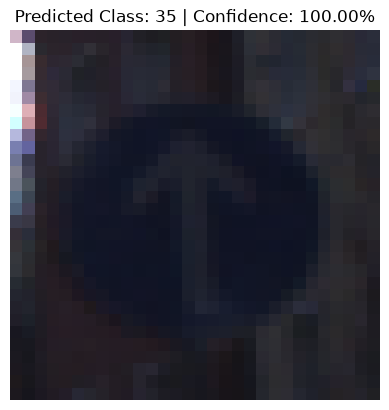

(35, 100.0)

In [24]:
def predict_traffic_sign(image_path, trained_model=model):
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(f'Image not found or unreadable: {image_path}')
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
    image_array = np.expand_dims(image.astype('float32') / 255.0, axis=0)
    probabilities = trained_model.predict(image_array, verbose=0)[0]
    predicted_class = int(np.argmax(probabilities))
    confidence = float(np.max(probabilities)) * 100
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Predicted Class: {predicted_class} | Confidence: {confidence:.2f}%')
    plt.show()
    return predicted_class, confidence

# Example prediction

predict_traffic_sign(r"C:\Users\aditi vinod padir\Downloads\archive\Test\12610.png")

In [20]:
import os

image_path = r"C:\Users\aditi vinod padir\Downloads\archive\Test\12610.png"

print("Image exists:", os.path.exists(image_path))

Image exists: True


## Project completion

- Dataset: GTSRB traffic sign images (43 classes)
- Preprocessing: resize to 30×30, RGB conversion, normalization
- Model: Convolutional Neural Network (CNN)
- Evaluation: test accuracy, test loss, classification report, confusion matrix
- Saved model: `traffic_sign_model.keras`

